# Phân tích giá nhà King County (Mỹ) — Ridge vs Random Forest

**Bài toán:** dự đoán **giá bán** của một căn nhà ở King County (gồm thành phố Seattle, bang Washington, Mỹ) **tại thời điểm giao dịch**, dựa trên đặc điểm căn nhà + vị trí. Đây là bài toán **định giá (hedonic pricing)** — giá là hàm của diện tích, chất lượng, vị trí — **không phải dự báo tương lai**, nên dữ liệu được chia ngẫu nhiên 80/20 chứ không chia theo thời gian.

- **Nguồn dữ liệu:** Kaggle — [House Sales in King County, USA](https://www.kaggle.com/datasets/harlfoxem/housesalesprediction) (`harlfoxem/housesalesprediction`), file `kc_house_data.csv`, 21.613 giao dịch từ 05/2014 đến 05/2015, đơn vị tiền USD.
- **Target chính:** `log(price)` — giá lệch phải rất mạnh nên lấy log; kết quả cuối quy về USD để đọc.
- **Mốc đánh giá:** test R² > 0,80 trên cả hai thang (log giá và giá thật USD).
- **Hai mô hình:** Ridge Regression và Random Forest Regression — đúng cặp mô hình của file báo cáo Studocu làm sườn.

**Cách chạy notebook này:** đặt file `kc_house_data.csv` cạnh file notebook này (cell dưới sẽ kiểm tra), hoặc sửa `DATA_DIR` trong cell 2. Chạy lần lượt từ trên xuống (Kernel → Restart & Run All).

In [1]:
# Cell 2 — imports + đường dẫn dữ liệu
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats

# Thư mục chứa file kc_house_data.csv — mặc định là thư mục của notebook này.
# Nếu file CSV ở chỗ khác, sửa DATA_DIR thành đường dẫn đó, ví dụ:
# DATA_DIR = Path("/home/hatch/workspace/king-county")
DATA_DIR = Path(".")
CSV_PATH = DATA_DIR / "kc_house_data.csv"
print("CSV:", CSV_PATH.resolve(), "| tồn tại:", CSV_PATH.exists())

plt.rcParams.update({"font.size": 11, "axes.edgecolor": "#333333",
                     "axes.labelcolor": "#101216", "text.color": "#101216",
                     "xtick.color": "#101216", "ytick.color": "#101216",
                     "figure.facecolor": "white", "axes.facecolor": "white"})
C_RIDGE, C_RF = "#1f77b4", "#2ca02c"

CSV: /home/hatch/workspace/your_files/notebooks/kc_house_data.csv | tồn tại: True


In [2]:
df = pd.read_csv(CSV_PATH)
print(f"Số dòng: {len(df):,} | Số cột: {df.shape[1]}")
print(f"Giao dịch từ {df['date'].min()} đến {df['date'].max()}")
df.head()

Số dòng: 21,613 | Số cột: 21
Giao dịch từ 20140502T000000 đến 20150527T000000


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


## 1. Thu thập dữ liệu

Bộ dữ liệu gồm **21.613 giao dịch** nhà ở King County trong khoảng 1 năm (05/2014–05/2015), 21 cột: mã nhà (`id`), ngày bán (`date`), giá bán (`price`), và các đặc điểm — số phòng ngủ/tắm, diện tích ở (`sqft_living`), diện tích đất (`sqft_lot`), số tầng, mặt tiền sông (`waterfront`), tầm nhìn (`view`), tình trạng (`condition`), hạng chất lượng (`grade`), diện tích tầng hầm, năm xây, năm sửa, mã bưu chính (`zipcode`), vĩ độ/kinh độ (`lat`, `long`), diện tích trung bình khu vực (`sqft_living15`, `sqft_lot15`).

Hai cột `sqft_living15`/`sqft_lot15` là **trung bình diện tích** của các nhà lân cận — không phải trung bình giá — nên không rò rỉ target. Không có cột nào suy ra từ giá bán.

In [3]:
print("--- THIẾU ---")
print(df.isna().sum().to_string())
print(f"\nSố dòng dính thiếu: {df.isna().any(axis=1).sum()} / {len(df)}")
print(f"\nDòng trùng chính xác: {df.duplicated().sum()}")
print(f"id trùng: {df['id'].duplicated().sum()} (cùng một căn nhà bán 2 lần trong kỳ)")
print(f"\nSố zipcode khác nhau: {df['zipcode'].nunique()}")
print(f"Số nhà có mặt tiền sông (waterfront=1): {(df['waterfront'] == 1).sum()}")
print(f"Năm xây: {df['yr_built'].min()}–{df['yr_built'].max()} | "
      f"Chưa từng sửa (yr_renovated=0): {(df['yr_renovated'] == 0).sum()} / {len(df)}")

--- THIẾU ---
id               0
date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
grade            0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
zipcode          0
lat              0
long             0
sqft_living15    0
sqft_lot15       0

Số dòng dính thiếu: 0 / 21613

Dòng trùng chính xác: 0
id trùng: 177 (cùng một căn nhà bán 2 lần trong kỳ)

Số zipcode khác nhau: 70
Số nhà có mặt tiền sông (waterfront=1): 163
Năm xây: 1900–2015 | Chưa từng sửa (yr_renovated=0): 20699 / 21613


## 2. Làm sạch và chuẩn hoá — kiểm tra thiếu, trùng, ngoại lai

**Không thiếu ô nào** trong toàn bộ file (0/21.613 dòng dính thiếu) — đây là bộ dữ liệu sạch nhất trong 4 bộ đã chạy, nên bước điền thiếu trong pipeline chỉ giữ lại cho an toàn.

**177 id trùng** không phải lỗi nhập liệu: cùng một căn nhà bán 2 lần trong kỳ 1 năm. Cột `id` chỉ là mã định danh nên sẽ bị bỏ, 177 dòng trùng này không ảnh hưởng gì.

In [4]:
pd.set_option("display.width", 200)
print("--- MÔ TẢ CÁC CỘT SỐ (phần trăm 1% / 99% cho thấy đuôi phân bố) ---")
display(df.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T.round(2))
print(f"\nGiá: skew = {df['price'].skew():.2f} | log(giá): skew = {np.log(df['price']).skew():.2f}")
print(f"Diện tích ở: skew = {df['sqft_living'].skew():.2f} | log: {np.log(df['sqft_living']).skew():.2f}")
print(f"Diện tích đất: skew = {df['sqft_lot'].skew():.2f} | log: {np.log(df['sqft_lot']).skew():.2f}")

--- MÔ TẢ CÁC CỘT SỐ (phần trăm 1% / 99% cho thấy đuôi phân bố) ---


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
id,21613.0,4.580302e+09,2.876566e+09,1000102.00,1.220339e+08,5.124803e+08,2.123049e+09,3.904930e+09,7.308900e+09,9.297300e+09,9.558728e+09,9.900000e+09
price,21613.0,5.400881e+05,3.671272e+05,75000.00,1.535004e+05,2.100000e+05,3.219500e+05,4.500000e+05,6.450000e+05,1.156480e+06,1.964400e+06,7.700000e+06
bedrooms,21613.0,3.370000e+00,9.300000e-01,0.00,2.000000e+00,2.000000e+00,3.000000e+00,3.000000e+00,4.000000e+00,5.000000e+00,6.000000e+00,3.300000e+01
bathrooms,21613.0,2.110000e+00,7.700000e-01,0.00,1.000000e+00,1.000000e+00,1.750000e+00,2.250000e+00,2.500000e+00,3.500000e+00,4.250000e+00,8.000000e+00
sqft_living,21613.0,2.079900e+03,9.184400e+02,290.00,7.200000e+02,9.400000e+02,1.427000e+03,1.910000e+03,2.550000e+03,3.760000e+03,4.978800e+03,1.354000e+04
sqft_lot,21613.0,1.510697e+04,4.142051e+04,520.00,1.013120e+03,1.800000e+03,5.040000e+03,7.618000e+03,1.068800e+04,4.333920e+04,2.130080e+05,1.651359e+06
floors,21613.0,1.490000e+00,5.400000e-01,1.00,1.000000e+00,1.000000e+00,1.000000e+00,1.500000e+00,2.000000e+00,2.000000e+00,3.000000e+00,3.500000e+00
waterfront,21613.0,1.000000e-02,9.000000e-02,0.00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
view,21613.0,2.300000e-01,7.700000e-01,0.00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,2.000000e+00,4.000000e+00,4.000000e+00
condition,21613.0,3.410000e+00,6.500000e-01,1.00,3.000000e+00,3.000000e+00,3.000000e+00,3.000000e+00,4.000000e+00,5.000000e+00,5.000000e+00,5.000000e+00



Giá: skew = 4.02 | log(giá): skew = 0.43
Diện tích ở: skew = 1.47 | log: -0.04
Diện tích đất: skew = 13.06 | log: 0.96


## 3. Mô tả dữ liệu — giá lệch phải rất mạnh

Giá bán trung bình **$540.088**, trung vị **$450.000**, rẻ nhất **$75.000**, đắt nhất **$7.700.000** (gấp 17 lần trung vị), p99 là $1.964.400. Độ lệch (skew) **4,02** — đuôi phải dài: một số ít nhà siêu đắt kéo trung bình lên cao hơn trung vị gần $90.000.

Lấy log thì skew chỉ còn **0,43** — phân bố gần đối xứng hơn nhiều. Đó là lý do target của bài này là `log(price)`: mô hình hồi quy làm việc tốt hơn khi target gần chuẩn, phần dư cũng gần chuẩn hơn. Diện tích cũng lệch phải tương tự (đất skew 13,06 → log còn 0,96) nên các cột diện tích cũng được lấy log.

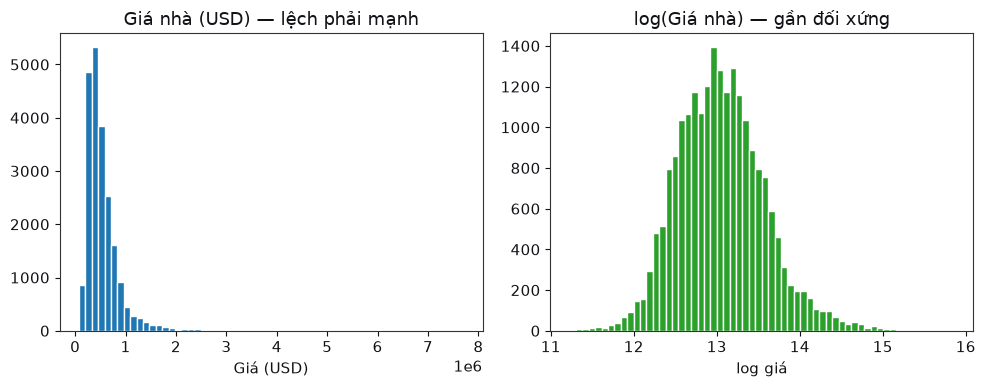

In [5]:
df["y"] = np.log(df["price"])
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].hist(df["price"], bins=60, color=C_RIDGE, edgecolor="white")
ax[0].set_title("Giá nhà (USD) — lệch phải mạnh")
ax[0].set_xlabel("Giá (USD)")
ax[1].hist(df["y"], bins=60, color=C_RF, edgecolor="white")
ax[1].set_title("log(Giá nhà) — gần đối xứng")
ax[1].set_xlabel("log giá")
plt.tight_layout()
plt.show()

Biểu đồ bên trái cho thấy hầu hết nhà tập trung ở $200.000–$700.000, còn đuôi phải kéo dài tới $7,7 triệu — một nhúm nhà siêu đắt. Biểu đồ bên phải (thang log) gần như hình chuông: đó chính là thứ mô hình hồi quy "thích" — sai số đo trên thang log cũng có nghĩa hơn, vì lệch 10% ở nhà $200.000 và nhà $2.000.000 là như nhau trên thang log.

In [6]:
num = df.select_dtypes("number")
print("--- TƯƠNG QUAN VỚI GIÁ (sắp xếp theo độ mạnh; bỏ log giá vì nó là target đã biến đổi) ---")
print(num.corr()["price"].drop(["price", "y"]).sort_values(key=abs, ascending=False).round(3).to_string())
print(f"\nTương quan log(giá) với giá (hiển nhiên, chỉ để tham khảo): {df['y'].corr(df['price']):.3f}")
print("\n--- ĐA CỘNG TUYẾN (các cặp tương quan cao với nhau) ---")
print(f"sqft_living – sqft_above: {df['sqft_living'].corr(df['sqft_above']):.2f}")
print(f"grade – sqft_living: {df['grade'].corr(df['sqft_living']):.2f}")
print(f"sqft_living – sqft_living15: {df['sqft_living'].corr(df['sqft_living15']):.2f}")

--- TƯƠNG QUAN VỚI GIÁ (sắp xếp theo độ mạnh; bỏ log giá vì nó là target đã biến đổi) ---
sqft_living      0.702
grade            0.667
sqft_above       0.606
sqft_living15    0.585
bathrooms        0.525
view             0.397
sqft_basement    0.324
bedrooms         0.308
lat              0.307
waterfront       0.266
floors           0.257
yr_renovated     0.126
sqft_lot         0.090
sqft_lot15       0.082
yr_built         0.054
zipcode         -0.053
condition        0.036
long             0.022
id              -0.017

Tương quan log(giá) với giá (hiển nhiên, chỉ để tham khảo): 0.892

--- ĐA CỘNG TUYẾN (các cặp tương quan cao với nhau) ---
sqft_living – sqft_above: 0.88
grade – sqft_living: 0.76
sqft_living – sqft_living15: 0.76


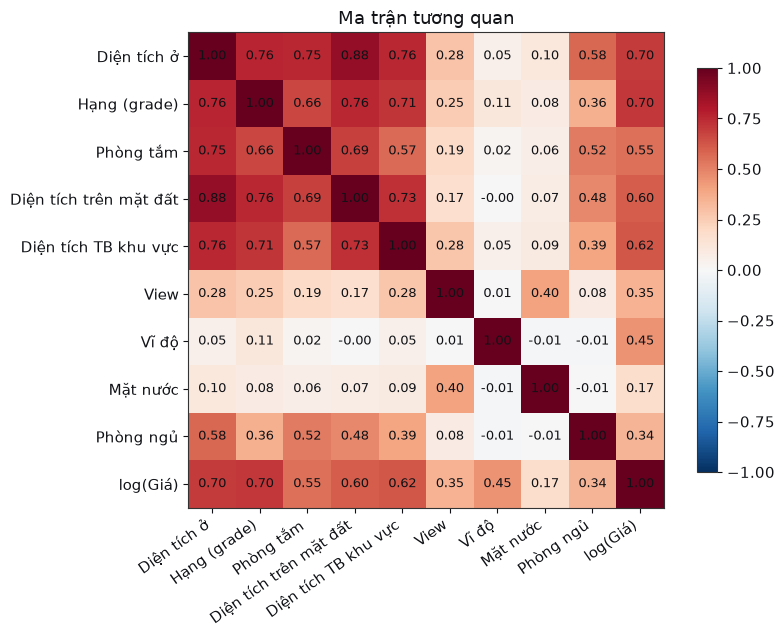

In [7]:
cols = ["sqft_living", "grade", "bathrooms", "sqft_above", "sqft_living15",
        "view", "lat", "waterfront", "bedrooms", "y"]
corr = df[cols].corr()
labels = ["Diện tích ở", "Hạng (grade)", "Phòng tắm", "Diện tích trên mặt đất",
          "Diện tích TB khu vực", "View", "Vĩ độ", "Mặt nước", "Phòng ngủ", "log(Giá)"]
fig, ax = plt.subplots(figsize=(8.5, 6.5))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(labels))); ax.set_yticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=35, ha="right"); ax.set_yticklabels(labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=9)
ax.set_title("Ma trận tương quan")
plt.colorbar(im, ax=ax, shrink=0.85)
plt.tight_layout()
plt.show()

Tương quan mạnh nhất với giá là **diện tích ở (0,70)** và **hạng chất lượng grade (0,67)**, rồi đến diện tích trên mặt đất (0,61), diện tích trung bình khu vực (0,59), số phòng tắm (0,53). Vị trí cũng có tín hiệu: view (0,40), vĩ độ lat (0,31), mặt tiền sông (0,27).

Nhưng có **đa cộng tuyến mạnh**: diện tích ở với diện tích trên mặt đất tương quan 0,88, grade với diện tích ở là 0,76 — các biến này "nói trùng" nhau. Với Ridge thì phạt L2 xử lý được chuyện này (hệ số được chia đều thay vì nhảy loạn); với Random Forest thì cây tự chọn biến nên cũng không sao. Đây là một lý do bộ này hợp với cả hai mô hình.

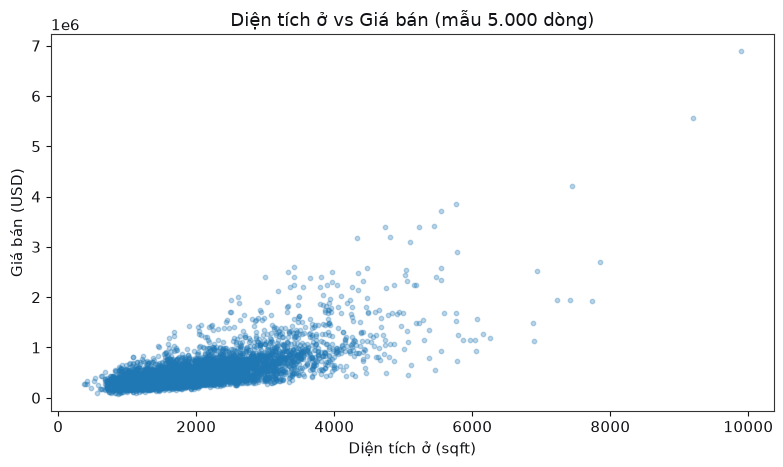

In [8]:
rng = np.random.RandomState(0)
idx = rng.choice(len(df), size=5000, replace=False)
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.scatter(df["sqft_living"].values[idx], df["price"].values[idx], s=10, alpha=0.3, color=C_RIDGE)
ax.set_xlabel("Diện tích ở (sqft)")
ax.set_ylabel("Giá bán (USD)")
ax.set_title("Diện tích ở vs Giá bán (mẫu 5.000 dòng)")
plt.tight_layout()
plt.show()

Đám mây điểm đi lên rõ rệt: nhà càng rộng càng đắt — đúng với tương quan 0,70. Nhưng đám mây có dạng **hình quạt xòe ra**: ở diện tích nhỏ, giá gom chặt quanh $200.000–$500.000; ở diện tích lớn, giá xòe từ $500.000 tới $7,7 triệu. Nghĩa là diện tích một mình không quyết định giá — cùng 4.000 sqft có thể là $600.000 hoặc $3 triệu, phần chênh đó nằm ở vị trí và hạng nhà. Đó cũng là lý do sau này phần dư lớn nhất tập trung ở nhà đắt.

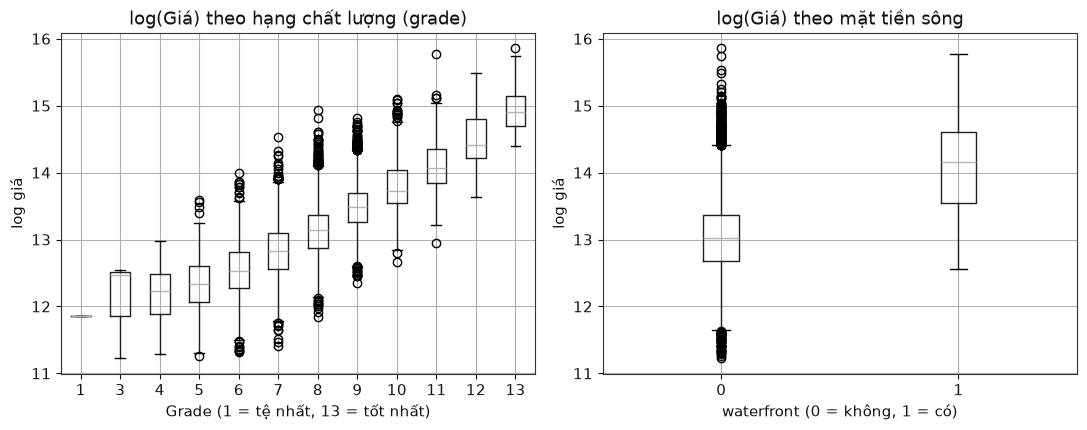

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))
df.boxplot(column="y", by="grade", ax=ax[0])
ax[0].set_title("log(Giá) theo hạng chất lượng (grade)")
ax[0].set_xlabel("Grade (1 = tệ nhất, 13 = tốt nhất)")
ax[0].set_ylabel("log giá")
df.boxplot(column="y", by="waterfront", ax=ax[1])
ax[1].set_title("log(Giá) theo mặt tiền sông")
ax[1].set_xlabel("waterfront (0 = không, 1 = có)")
ax[1].set_ylabel("log giá")
plt.suptitle("")
plt.tight_layout()
plt.show()

**Grade:** giá tăng đều theo hạng — từ grade 3–4 (trung vị log giá thấp nhất) lên grade 11–13 (cao nhất). Grade 7 là phổ biến nhất và cũng là "điểm giữa" của thị trường. Hộp càng lên cao càng dài ra: nhà hạng cao có biên độ giá rộng hơn.

**Waterfront:** chỉ 163 nhà có mặt tiền sông, nhưng giá trung bình của chúng là **$1.661.876**, gấp 3 lần nhóm còn lại ($531.564). Hộp của nhóm waterfront nằm hẳn phía trên — mặt tiền sông là một trong những "vé đắt" nhất của thị trường này. (Lưu ý: hộp nhỏ vì chỉ 163 nhà, ước lượng kém ổn định hơn.)

Top 5 zipcode đắt nhất (giá trung bình):
              mean  count
zipcode                  
98039    2160607.0     50
98004    1355927.0    317
98040    1194230.0    282
98112    1095499.0    269
98102     901258.0    105

Top 5 zipcode rẻ nhất:
             mean  count
zipcode                 
98148    284909.0     57
98001    280805.0    362
98032    251296.0    125
98168    240328.0    269
98002    234284.0    199


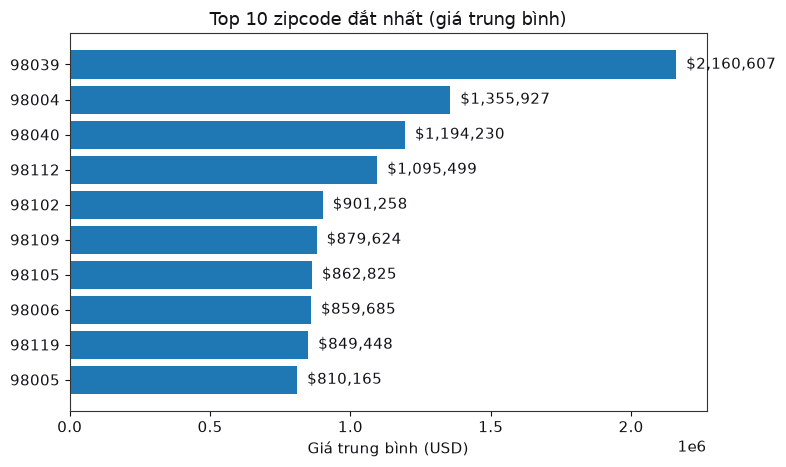

In [10]:
z = df.groupby("zipcode")["price"].agg(["mean", "count"]).sort_values("mean", ascending=False)
print("Top 5 zipcode đắt nhất (giá trung bình):")
print(z.head(5).round(0).to_string())
print("\nTop 5 zipcode rẻ nhất:")
print(z.tail(5).round(0).to_string())

top10 = z.head(10).sort_values("mean")
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.barh(top10.index.astype(str), top10["mean"], color=C_RIDGE)
ax.set_xlabel("Giá trung bình (USD)")
ax.set_title("Top 10 zipcode đắt nhất (giá trung bình)")
for i, v in enumerate(top10["mean"]):
    ax.text(v, i, f"  ${v:,.0f}", va="center")
plt.tight_layout()
plt.show()

Vị trí — thể hiện qua zipcode — là yếu tố đắt nhất của bài này. **98039 (Medina) trung bình $2.160.607**, gấp 9 lần zipcode rẻ nhất **98002 ($234.284)**. Top 10 toàn là các khu ven hồ phía đông Seattle (Medina, Clyde Hill, Hunts Point...).

Sau này sẽ thấy: hệ số Ridge lớn nhất toàn là zipcode (98039: +0,79), còn Random Forest thì dùng vĩ độ/kinh độ để "học" vị trí thay cho zipcode. Cùng một thông tin vị trí, hai mô hình mã hoá theo hai cách khác nhau.

In [11]:
print("--- NGOẠI LAI THEO IQR (vượt Q1 − 1,5·IQR hoặc Q3 + 1,5·IQR) ---")
for c in ["price", "bedrooms", "bathrooms", "sqft_living", "sqft_lot", "sqft_above",
          "sqft_basement", "yr_built", "lat", "long", "sqft_living15", "sqft_lot15"]:
    s = df[c].dropna()
    q1, q3 = s.quantile(.25), s.quantile(.75)
    iqr = q3 - q1
    n = ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()
    print(f"{c:16s} ngoại lai = {n:5d} ({100*n/len(s):4.1f}%)  min = {s.min():>10,.0f}  max = {s.max():>10,.0f}")
print(f"\nbedrooms = 33: {(df['bedrooms'] == 33).sum()} dòng | bedrooms = 0: {(df['bedrooms'] == 0).sum()} dòng")

--- NGOẠI LAI THEO IQR (vượt Q1 − 1,5·IQR hoặc Q3 + 1,5·IQR) ---
price            ngoại lai =  1146 ( 5.3%)  min =     75,000  max =  7,700,000
bedrooms         ngoại lai =   546 ( 2.5%)  min =          0  max =         33
bathrooms        ngoại lai =   571 ( 2.6%)  min =          0  max =          8
sqft_living      ngoại lai =   572 ( 2.6%)  min =        290  max =     13,540
sqft_lot         ngoại lai =  2425 (11.2%)  min =        520  max =  1,651,359
sqft_above       ngoại lai =   611 ( 2.8%)  min =        290  max =      9,410
sqft_basement    ngoại lai =   496 ( 2.3%)  min =          0  max =      4,820
yr_built         ngoại lai =     0 ( 0.0%)  min =      1,900  max =      2,015
lat              ngoại lai =     2 ( 0.0%)  min =         47  max =         48
long             ngoại lai =   256 ( 1.2%)  min =       -123  max =       -121
sqft_living15    ngoại lai =   544 ( 2.5%)  min =        399  max =      6,210
sqft_lot15       ngoại lai =  2194 (10.2%)  min =        651  max 

Ngoại lai tập trung ở **giá (5,3% — 1.146 dòng)** và **diện tích đất (11,2%, max 1.651.359 sqft)**. Có vài dòng dị biệt rõ: 1 nhà ghi 33 phòng ngủ, 13 nhà ghi 0 phòng ngủ — nhiều khả năng là lỗi nhập liệu, nhưng không xóa.

Cách xử lý ở đây là **winsorise 1%/99%**: chặn các giá trị vượt phân vị 1%/99% của train về đúng mốc đó, thay vì xóa dòng. Nhà $7,7 triệu sau winsorise vẫn là nhà đắt nhất (chỉ bị kéo về $1,96 triệu ở thang đặc trưng, còn target log giá thì giữ nguyên) — giữ được thông tin "nhà đắt vẫn là nhà đắt", chỉ không để một vài điểm kéo lệch mô hình.

## 4. Tiền xử lý — pipeline 9 bước

1. **Bỏ `id` và `date`:** `id` chỉ là mã định danh; `date` không dùng vì đây là định giá tại thời điểm giao dịch, không phải dự báo theo thời gian.
2. **Target `log(price)`:** giá lệch phải mạnh (skew 4,02, max gấp 17 lần trung vị) nên log kéo đuôi phải về, phần dư gần chuẩn hơn; kết quả cuối quy về USD để đọc.
3. **Log các cột diện tích** (`sqft_living`, `sqft_lot`, `sqft_above`, `sqft_living15`, `sqft_lot15`): diện tích cũng lệch phải và quan hệ diện tích–giá gần tuyến tính hơn ở thang log.
4. **Feature mới, không rò rỉ:** `Age = 2015 − yr_built` (tuổi nhà dễ đọc hơn năm xây); `renovated = yr_renovated > 0` (đã sửa hay chưa); `yrs_since_renov`; `total_rooms = bedrooms + bathrooms`; `sqft_per_room` (diện tích mỗi phòng).
5. **Winsorise 1%/99% theo train:** chặn đuôi cực đoan thay vì xóa dòng (xem mục trên).
6. **Median/mode impute** giữ trong pipeline cho an toàn dù file này 0 ô thiếu.
7. **OneHot cho `zipcode` (70 giá trị):** zipcode là danh mục, không có thứ tự — không được mã hoá số 98001 < 98002.
8. **StandardScaler cho Ridge** (Ridge phạt hệ số nên cần cùng thang đo); Random Forest không cần scaler vì cây chỉ chia ngưỡng.
9. **Chia ngẫu nhiên 80/20, `random_state=42`:** train 17.290 / test 4.323. Mọi tham số tiền xử lý (median, winsorise, scaler, OneHot) chỉ học từ TRAIN — không học từ test.

In [12]:
# Cell — đặc trưng + chia train/test + pipeline tiền xử lý (đúng thiết kế gốc)
from sklearn.model_selection import train_test_split

df["Age"] = 2015 - df["yr_built"]
df["renovated"] = (df["yr_renovated"] > 0).astype(int)
df["yrs_since_renov"] = np.where(df["renovated"] == 1, 2015 - df["yr_renovated"], 0)
df["total_rooms"] = df["bedrooms"] + df["bathrooms"]
df["sqft_per_room"] = df["sqft_living"] / df["total_rooms"].clip(lower=1)
for c in ["sqft_living", "sqft_lot", "sqft_above", "sqft_living15", "sqft_lot15"]:
    df[f"log_{c}"] = np.log(df[c])
df["y"] = np.log(df["price"])

NUM = ["log_sqft_living", "log_sqft_lot", "log_sqft_above", "log_sqft_living15",
       "log_sqft_lot15", "bedrooms", "bathrooms", "floors", "waterfront", "view",
       "condition", "grade", "sqft_basement", "Age", "renovated", "yrs_since_renov",
       "total_rooms", "sqft_per_room", "lat", "long"]
CAT = ["zipcode"]
FEATS = NUM + CAT

X = df[FEATS]
y = df["y"]
y_raw = df["price"]
X_tr, X_te, y_tr, y_te, yraw_tr, yraw_te = train_test_split(
    X, y, y_raw, test_size=0.2, random_state=42)
print(f"train {len(X_tr):,} | test {len(X_te):,} | features {len(FEATS)} "
      f"({len(NUM)} số + zipcode OneHot 70 giá trị)")

# Ngưỡng winsorise học từ TRAIN (1% / 99%)
lo = X_tr[NUM].quantile(0.01).to_numpy()
hi = X_tr[NUM].quantile(0.99).to_numpy()

from sklearn.base import BaseEstimator, TransformerMixin
class Winsoriser(BaseEstimator, TransformerMixin):
    """Chặn mỗi cột số về phân vị 1%/99% của train."""
    def fit(self, X, y=None):
        self.n_features_in_ = np.asarray(X).shape[1]
        return self
    def transform(self, X):
        X = np.asarray(X, dtype=float).copy()
        return np.clip(X, lo, hi)

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

def prep(scaler):
    num_pipe = (make_pipeline(SimpleImputer(strategy="median"), Winsoriser(), scaler)
                if scaler else make_pipeline(SimpleImputer(strategy="median"), Winsoriser()))
    cat_pipe = make_pipeline(SimpleImputer(strategy="most_frequent"),
                             OneHotEncoder(handle_unknown="ignore"))
    return ColumnTransformer([("num", num_pipe, NUM), ("cat", cat_pipe, CAT)])

train 17,290 | test 4,323 | features 21 (20 số + zipcode OneHot 70 giá trị)


## 5. Cơ sở lý thuyết — Ridge vs Random Forest (ngắn gọn)

**Ridge Regression** = hồi quy tuyến tính + phạt L2 (cộng thêm α·Σβ² vào hàm mất mát). Mạnh khi quan hệ gần tuyến tính sau biến đổi log, hệ số đọc được trực tiếp (mỗi zipcode cộng/trừ bao nhiêu vào log giá), và ổn định với đa cộng tuyến nhờ phạt L2 chia đều hệ số. Yếu khi quan hệ phi tuyến (hiệu ứng vị trí kiểu "ven hồ + hạng cao đắt hơn tổng hai phần"). α được chọn bằng kiểm chứng chéo 5-fold trong train.

**Random Forest** = trung bình của 300 cây quyết định, mỗi cây học trên một mẫu bootstrap và chỉ xét ngẫu nhiên một tập con feature ở mỗi lần chia. Mạnh khi có tương tác phi tuyến (vị trí × diện tích × grade) mà không cần giả định dạng hàm; yếu ở chỗ khó giải thích từng hệ số, dễ học thuộc train (overfit), và dự báo bị chặn trong khoảng giá đã thấy ở train nên nhà siêu đắt hay bị đoán thấp.

**Khác biệt chính trong bài này:** Ridge thắng ở tính giải thích (đọc được giá trị từng khu vực), RF thắng ở độ chính xác nhờ bắt được phi tuyến của vị trí — nhưng chênh lệch nhỏ (R²_log 0,8793 so với 0,8867) vì sau log thì quan hệ đã gần tuyến tính.

In [13]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

def metrics(name, y_true_log, pred_log, y_true_raw):
    """Đánh giá cả hai thang: log giá (thang mô hình học) và USD (thang đọc)."""
    usd_pred = np.exp(pred_log)
    m = {
        "R2_log": round(float(r2_score(y_true_log, pred_log)), 4),
        "R2_raw": round(float(r2_score(y_true_raw, usd_pred)), 4),
        "MAE_log": round(float(mean_absolute_error(y_true_log, pred_log)), 4),
        "MAE_raw": round(float(mean_absolute_error(y_true_raw, usd_pred)), 1),
        "RMSE_raw": round(float(mean_squared_error(y_true_raw, usd_pred) ** 0.5), 1),
        "MedAPE_pct": round(float(np.median(np.abs(usd_pred / y_true_raw - 1)) * 100), 2),
    }
    print(name, m)
    return m

# Baseline "đoán trung bình": mọi nhà cùng một giá = giá trung bình train (thang log)
pred_mean = np.full(len(X_te), y_tr.mean())
res_mean = metrics("Mean baseline", y_te, pred_mean, yraw_te)

Mean baseline {'R2_log': -0.0006, 'R2_raw': -0.0495, 'MAE_log': 0.4187, 'MAE_raw': 229794.7, 'RMSE_raw': 398323.3, 'MedAPE_pct': 34.81}


In [14]:
import time
from sklearn.linear_model import RidgeCV

t = time.time()
ridge = make_pipeline(prep(StandardScaler()),
                      RidgeCV(alphas=[0.1, 1, 10, 100, 1000], cv=5))
ridge.fit(X_tr, y_tr)
print(f"Ridge fit xong sau {time.time() - t:.1f}s | alpha chọn được: {ridge[-1].alpha_}")
pred_ridge = ridge.predict(X_te)
res_ridge = metrics("Ridge", y_te, pred_ridge, yraw_te)
res_ridge["R2_train_log"] = round(float(r2_score(y_tr, ridge.predict(X_tr))), 4)
res_ridge["alpha"] = float(ridge[-1].alpha_)
print("Ridge R² train (log):", res_ridge["R2_train_log"])

Ridge fit xong sau 3.1s | alpha chọn được: 0.1
Ridge {'R2_log': 0.8793, 'R2_raw': 0.8366, 'MAE_log': 0.1354, 'MAE_raw': 79091.0, 'RMSE_raw': 157178.0, 'MedAPE_pct': 9.95}
Ridge R² train (log): 0.878


In [15]:
from sklearn.model_selection import KFold, cross_val_score

kf = KFold(5, shuffle=True, random_state=42)
cv_ridge = cross_val_score(ridge, X, y, cv=kf, scoring="r2")
res_ridge["CV_R2_mean"] = round(float(cv_ridge.mean()), 4)
res_ridge["CV_R2_std"] = round(float(cv_ridge.std()), 4)
print("Ridge 5-fold CV R² (log):", np.round(cv_ridge, 4))
print(f"CV trung bình: {res_ridge['CV_R2_mean']} ± {res_ridge['CV_R2_std']}")

Ridge 5-fold CV R² (log): [0.8793 0.8775 0.8717 0.879  0.8782]
CV trung bình: 0.8771 ± 0.0028


### Nhận xét Ridge

Ridge đạt **R²_log 0,8793 / R²_raw 0,8366** trên test, MAE **$79.091**, sai số % trung vị **9,95%** — vượt mốc 0,80 trên cả hai thang. Điểm train (0,878) gần như trùng điểm test (0,8793) và CV (0,8771 ± 0,0028) cũng vậy: mô hình ổn định, không học vẹt (chi tiết ở mục 7).

Baseline đoán trung bình chỉ được R²_log −0,0006, MAE $229.795 — Ridge tốt hơn baseline gần 3 lần về MAE.

In [16]:
from sklearn.ensemble import RandomForestRegressor

t = time.time()
rf = make_pipeline(prep(None),
                   RandomForestRegressor(n_estimators=300, min_samples_leaf=2,
                                         n_jobs=-1, random_state=42))
rf.fit(X_tr, y_tr)
print(f"RF fit xong sau {time.time() - t:.1f}s")
pred_rf = rf.predict(X_te)
res_rf = metrics("RandomForest", y_te, pred_rf, yraw_te)
res_rf["R2_train_log"] = round(float(r2_score(y_tr, rf.predict(X_tr))), 4)
print("RF R² train (log):", res_rf["R2_train_log"])

RF fit xong sau 149.9s


RandomForest {'R2_log': 0.8867, 'R2_raw': 0.8545, 'MAE_log': 0.1274, 'MAE_raw': 74653.5, 'RMSE_raw': 148314.2, 'MedAPE_pct': 8.83}


RF R² train (log): 0.9741


In [17]:
# RF 5-fold CV — cell này chạy lâu (~13 phút) vì mỗi fold fit lại 300 cây.
# Giữ nguyên để kiểm chứng độ ổn định đúng như lần chạy gốc.
cv_rf = cross_val_score(rf, X, y, cv=kf, scoring="r2")
res_rf["CV_R2_mean"] = round(float(cv_rf.mean()), 4)
res_rf["CV_R2_std"] = round(float(cv_rf.std()), 4)
print("RF 5-fold CV R² (log):", np.round(cv_rf, 4))
print(f"CV trung bình: {res_rf['CV_R2_mean']} ± {res_rf['CV_R2_std']}")

RF 5-fold CV R² (log): [0.887  0.8844 0.8788 0.8897 0.8856]
CV trung bình: 0.8851 ± 0.0036


### So sánh 2 mô hình (test 4.323 dòng)

| Mô hình | R² log giá | R² giá thật (USD) | MAE (USD) | Sai số % trung vị | R² train | CV 5-fold |
|---|---|---|---|---|---|---|
| Baseline (đoán trung bình) | −0,0006 | −0,0495 | 229.795 | 34,81% | — | — |
| Ridge (α=0,1) | 0,8793 | 0,8366 | 79.091 | 9,95% | 0,878 | 0,8771 ± 0,0028 |
| Random Forest (300 cây) | 0,8867 | 0,8545 | 74.654 | 8,83% | 0,9741 | 0,8851 ± 0,0036 |

**Cả hai đều vượt mốc 0,80 trên cả hai thang; RF thắng Ridge nhẹ** (R²_log hơn 0,0074, MAE thấp hơn ~$4.400). RF có gap train–test (0,9741 → 0,8867) nhưng CV ổn định (0,8851 ± 0,0036) nên không phải may mắn — chi tiết ở mục kiểm tra học vẹt bên dưới.

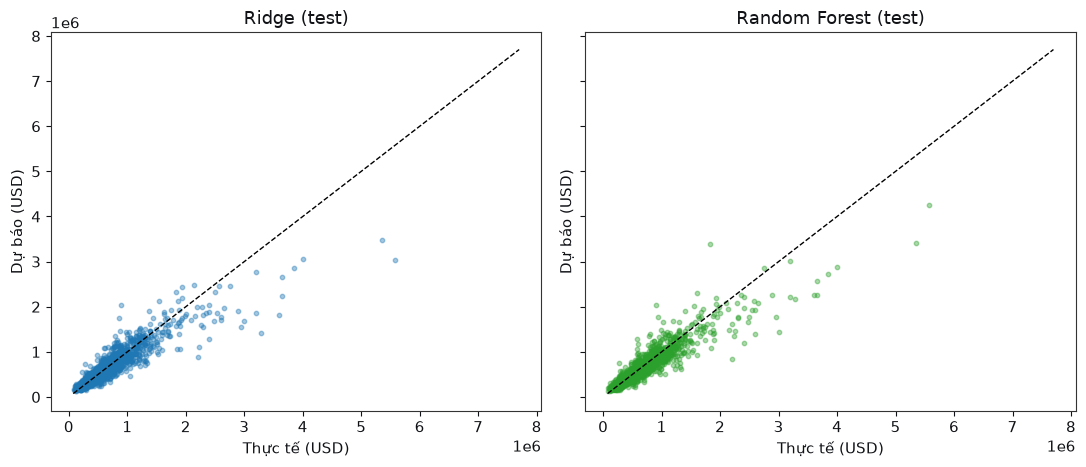

In [18]:
rng = np.random.RandomState(0)
idx = rng.choice(len(yraw_te), size=min(3000, len(yraw_te)), replace=False)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.8), sharex=True, sharey=True)
for a, pred, name, c in [(ax[0], np.exp(pred_ridge), "Ridge", C_RIDGE),
                         (ax[1], np.exp(pred_rf), "Random Forest", C_RF)]:
    a.scatter(yraw_te.values[idx], pred[idx], s=10, alpha=0.4, color=c)
    lims = [75000, 7700000]
    a.plot(lims, lims, "k--", lw=1)
    a.set_title(f"{name} (test)")
    a.set_xlabel("Thực tế (USD)")
    a.set_ylabel("Dự báo (USD)")
plt.tight_layout()
plt.show()

Hai đám mây điểm đều bám sát đường chéo đứt nét (đường "đoán đúng hoàn toàn") — càng gần đường chéo càng tốt. Điểm khác biệt: ở góc trên-phải (nhà trên $2 triệu), các điểm nằm **dưới** đường chéo, tức cả hai mô hình đều **đoán thấp nhà siêu đắt**. Với RF thì đây là giới hạn ngoại suy của cây: cây không thể dự báo ngoài khoảng giá đã thấy ở train. Với Ridge thì log target kéo đuôi về nên nhà đắt nhất vẫn bị "kéo" xuống.

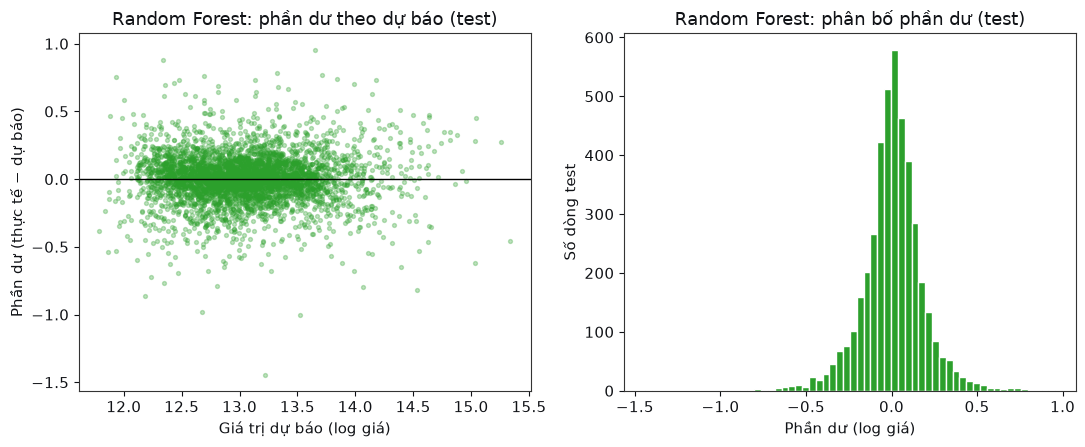

In [19]:
resid_rf = y_te.values - pred_rf
resid_ridge = y_te.values - pred_ridge
fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))
ax[0].scatter(pred_rf, resid_rf, s=8, alpha=0.3, color=C_RF)
ax[0].axhline(0, color="black", lw=1)
ax[0].set_xlabel("Giá trị dự báo (log giá)")
ax[0].set_ylabel("Phần dư (thực tế − dự báo)")
ax[0].set_title("Random Forest: phần dư theo dự báo (test)")
ax[1].hist(resid_rf, bins=60, color=C_RF, edgecolor="white")
ax[1].set_xlabel("Phần dư (log giá)")
ax[1].set_ylabel("Số dòng test")
ax[1].set_title("Random Forest: phân bố phần dư (test)")
plt.tight_layout()
plt.show()

Phần dư (sai số) của RF rải đều quanh 0, không có hình phễu hay đường cong rõ rệt — tức mô hình không bỏ sót một xu hướng lớn nào. Histogram phần dư gần hình chuông, hơi lệch phải: đuôi phải là những nhà bị đoán thấp (thực tế cao hơn dự báo nhiều).

Kiểm tra kỹ hơn bằng thập phân vị dự báo: trung bình phần dư chỉ −0,018 đến +0,022 ở mọi decile (gần 0), nhưng độ lệch chuẩn tăng dần 0,154 → 0,239 ở decile cao nhất — **nhà siêu đắt khó đoán nhất**, đúng như đã thấy ở biểu đồ thực tế–dự báo.

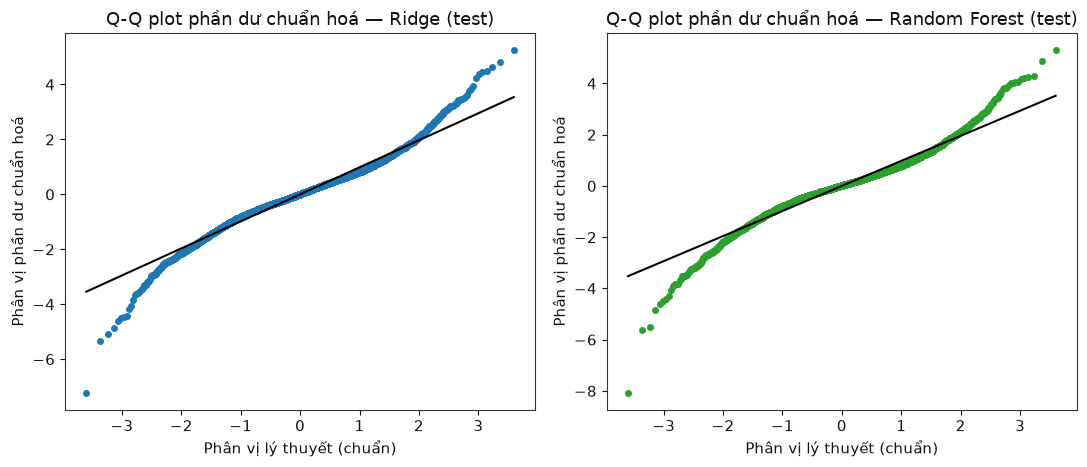

In [20]:
def std_resid(r):
    return (r - r.mean()) / r.std()

fig, ax = plt.subplots(1, 2, figsize=(11, 4.8))
for a, r, name, c in [(ax[0], std_resid(resid_ridge), "Ridge", C_RIDGE),
                      (ax[1], std_resid(resid_rf), "Random Forest", C_RF)]:
    stats.probplot(r, dist="norm", plot=a)
    a.get_lines()[0].set_markerfacecolor(c)
    a.get_lines()[0].set_markeredgecolor(c)
    a.get_lines()[0].set_markersize(4)
    a.get_lines()[1].set_color("black")
    a.set_title(f"Q-Q plot phần dư chuẩn hoá — {name} (test)")
    a.set_xlabel("Phân vị lý thuyết (chuẩn)")
    a.set_ylabel("Phân vị phần dư chuẩn hoá")
plt.tight_layout()
plt.show()

## 6. Kiểm định giả thiết — phần dư có gần chuẩn không?

Q-Q plot so phần dư chuẩn hoá (điểm) với phân phối chuẩn lý thuyết (đường thẳng). Nếu phần dư đúng chuẩn thì điểm nằm trên đường thẳng.

Cả hai mô hình đều bám đường thẳng ở giữa, nhưng **đuôi hai đầu cong ra ngoài** — nhất là đuôi phải (nhà bị đoán thấp nhiều) và đuôi trái (nhà bị đoán cao). Nghĩa là phần dư **gần chuẩn nhưng đuôi nặng hơn chuẩn**: có nhiều ngoại lai hơn phân phối chuẩn dự kiến. Điều này không làm hỏng R², nhưng nhắc rằng khoảng tin cậy kiểu "±2 độ lệch chuẩn" sẽ lạc quan hơn thực tế ở nhà đắt. Log target đã cải thiện nhiều (skew 4,02 → 0,43), nhưng chưa triệt tiêu hẳn đuôi nặng — vì đuôi nặng đến từ chính thị trường (nhà siêu đắt), không phải từ lỗi biến đổi.

In [21]:
dec = pd.qcut(pred_rf, 10, labels=False)
diag = pd.DataFrame({"decile": dec, "resid": resid_rf}).groupby("decile")["resid"].agg(["mean", "std", "count"])
print("Random Forest — phần dư theo thập phân vị dự báo (test):")
display(diag.round(3))
print("\nVí dụ 1 dòng test (dòng đầu tiên của test):")
print(f"Thực tế: ${yraw_te.iloc[0]:,.0f} | Ridge đoán: ${np.exp(pred_ridge[0]):,.0f} | RF đoán: ${np.exp(pred_rf[0]):,.0f}")

Random Forest — phần dư theo thập phân vị dự báo (test):


,mean,std,count
decile,,,
0,0.019,0.214,433
1,0.017,0.173,432
2,-0.002,0.180,432
3,-0.018,0.161,432
4,-0.006,0.160,433
5,0.009,0.154,432
6,0.005,0.166,432
7,0.022,0.157,432
8,0.008,0.170,432



Ví dụ 1 dòng test (dòng đầu tiên của test):
Thực tế: $365,000 | Ridge đoán: $376,498 | RF đoán: $375,481


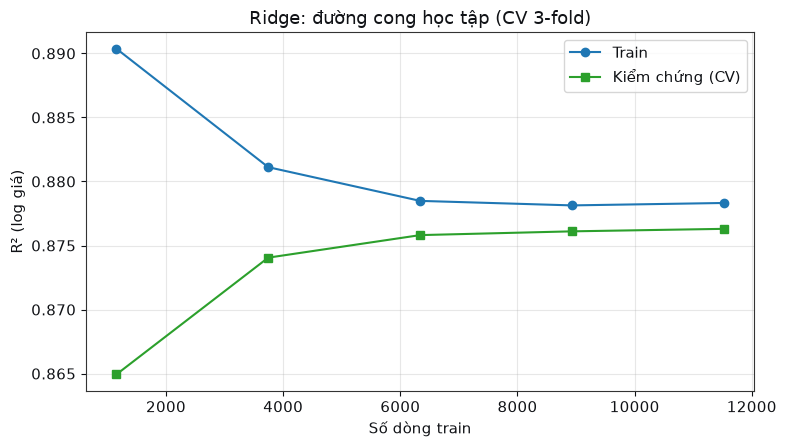

In [22]:
from sklearn.model_selection import learning_curve

train_sizes, train_scores, test_scores = learning_curve(
    ridge, X_tr, y_tr, cv=3, train_sizes=np.linspace(0.1, 1.0, 5),
    scoring="r2", n_jobs=-1)
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.plot(train_sizes, train_scores.mean(axis=1), "o-", color=C_RIDGE, label="Train")
ax.plot(train_sizes, test_scores.mean(axis=1), "s-", color=C_RF, label="Kiểm chứng (CV)")
ax.set_xlabel("Số dòng train")
ax.set_ylabel("R² (log giá)")
ax.set_title("Ridge: đường cong học tập (CV 3-fold)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

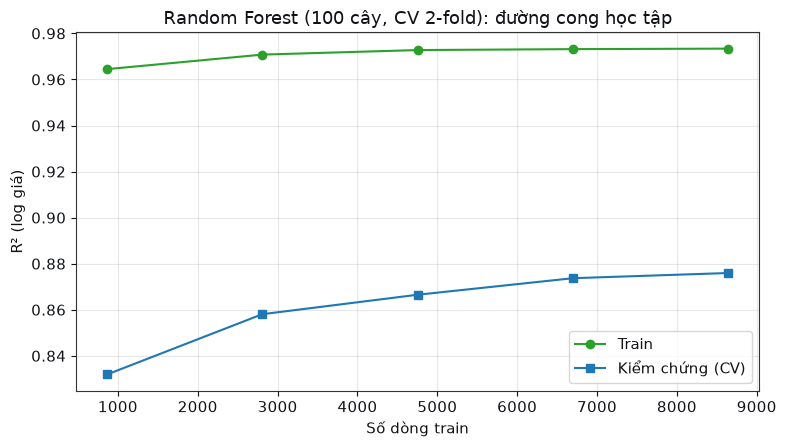

In [23]:
# Đường cong học tập RF: dùng 100 cây (thay vì 300) và CV 2-fold để chạy trong
# thời gian hợp lý. Hình dạng đường cong mới là điều cần đọc, không phải giá trị tuyệt đối.
rf_lc = make_pipeline(prep(None),
                      RandomForestRegressor(n_estimators=100, min_samples_leaf=2,
                                            n_jobs=-1, random_state=42))
ts, tr_s, te_s = learning_curve(
    rf_lc, X_tr, y_tr, cv=2, train_sizes=np.linspace(0.1, 1.0, 5),
    scoring="r2", n_jobs=-1)
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.plot(ts, tr_s.mean(axis=1), "o-", color=C_RF, label="Train")
ax.plot(ts, te_s.mean(axis=1), "s-", color=C_RIDGE, label="Kiểm chứng (CV)")
ax.set_xlabel("Số dòng train")
ax.set_ylabel("R² (log giá)")
ax.set_title("Random Forest (100 cây, CV 2-fold): đường cong học tập")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Đọc đường cong học tập

**Ridge:** đường train và đường kiểm chứng gần như trùng nhau ngay từ ít dữ liệu và cùng hội tụ quanh 0,88 — thêm dữ liệu không cải thiện bao nhiêu. Đây là dấu hiệu của mô hình **độ lệch (bias) cao, phương sai (variance) thấp**: Ridge đã học hết những gì dạng tuyến tính cho phép, nút thắt nằm ở dạng hàm chứ không phải lượng dữ liệu.

**Random Forest:** đường train ở rất cao (~0,97) còn đường kiểm chứng tăng dần theo dữ liệu rồi phẳng quanh 0,88 — khoảng hở train–test vẫn còn nhưng thu hẹp chậm khi thêm dữ liệu. Cây nhớ được train (overfit nhẹ) nhưng kiểm chứng vẫn tăng, tức thêm dữ liệu vẫn giúp một chút. Tuy nhiên đường kiểm chứng đã phẳng ở cuối: thêm dữ liệu nữa cũng chỉ cải thiện nhỏ — nút thắt nằm ở feature, không phải lượng dữ liệu.

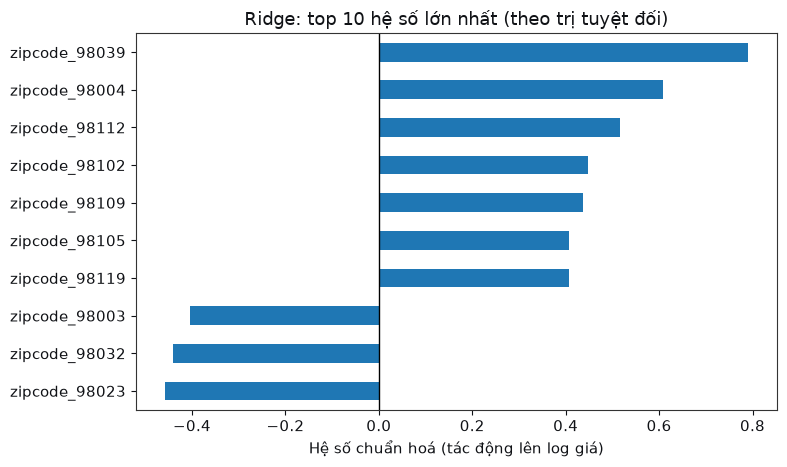

Top 10 hệ số Ridge:
zipcode_98039    0.790
zipcode_98004    0.609
zipcode_98112    0.517
zipcode_98023   -0.458
zipcode_98102    0.448
zipcode_98032   -0.440
zipcode_98109    0.438
zipcode_98105    0.408
zipcode_98119    0.407
zipcode_98003   -0.405


In [24]:
ohe = ridge[0].named_transformers_["cat"][1]
cat_names = list(ohe.get_feature_names_out(CAT))
names = NUM + cat_names
coefs = pd.Series(dict(zip(names, np.round(ridge[-1].coef_, 3))))
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(10).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.8))
top.plot.barh(ax=ax, color=C_RIDGE)
ax.axvline(0, color="black", lw=1)
ax.set_xlabel("Hệ số chuẩn hoá (tác động lên log giá)")
ax.set_title("Ridge: top 10 hệ số lớn nhất (theo trị tuyệt đối)")
plt.tight_layout()
plt.show()
print("Top 10 hệ số Ridge:")
print(coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(10).round(3).to_string())

Top 10 hệ số Ridge **toàn là zipcode** — tức vị trí. Lớn nhất là **98039 (Medina) +0,79**, rồi 98004 (+0,609), 98112 (+0,517), 98102 (+0,448); chiều ngược lại 98023 (−0,458), 98032 (−0,44). Vì hệ số đã chuẩn hoá nên đọc được trực tiếp: ở cùng diện tích, cùng hạng nhà, chỉ khác zipcode 98039 với zipcode trung bình thì log giá chênh nhau 0,79 — tức giá gấp e^0,79 ≈ 2,2 lần.

Các hệ số feature khác đều nhỏ hơn nhiều (lớn nhất là `total_rooms` +0,148, `grade` +0,107). Nghĩa là sau khi đã tính vị trí, diện tích và hạng nhà chỉ còn là điểm cộng/trừ nhỏ. Đây chính là điểm mạnh của Ridge: đọc được "giá trị" của từng khu vực bằng một con số.

RF permutation importance (mẫu 2.000 dòng test, n_repeats=5):
lat                  0.5960
log_sqft_living      0.2178
grade                0.1735
long                 0.0845
Age                  0.0224
log_sqft_living15    0.0160
view                 0.0154
log_sqft_lot         0.0075
log_sqft_above       0.0068
log_sqft_lot15       0.0049
zipcode              0.0032
condition            0.0022
sqft_per_room        0.0008
total_rooms          0.0005
bathrooms            0.0003
bedrooms             0.0002
yrs_since_renov      0.0001
renovated            0.0001
waterfront           0.0000
floors               0.0000
sqft_basement       -0.0001


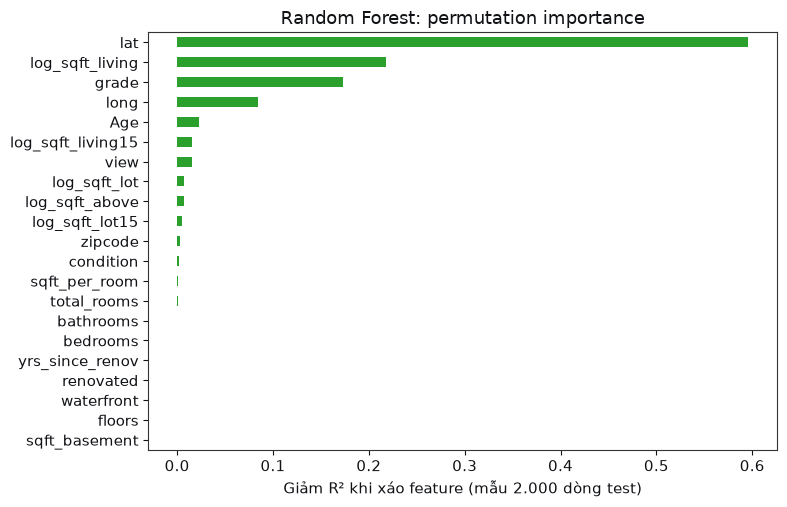

In [25]:
from sklearn.inspection import permutation_importance

# Chỉ chạy trên mẫu 2.000 dòng test ngẫu nhiên (seed 42), n_repeats=5 — để kịp thời gian.
# Giá trị tuyệt đối sẽ lệch nhẹ so với chạy toàn bộ test, nhưng thứ hạng các feature giữ nguyên.
rng = np.random.RandomState(42)
idx_perm = rng.choice(len(X_te), size=2000, replace=False)
X_te_s = X_te.iloc[idx_perm]
y_te_s = y_te.iloc[idx_perm]
perm = permutation_importance(rf, X_te_s, y_te_s, n_repeats=5, random_state=42, n_jobs=-1)
perm_imp = pd.Series(dict(zip(FEATS, np.round(perm.importances_mean, 4)))).sort_values()
print("RF permutation importance (mẫu 2.000 dòng test, n_repeats=5):")
print(perm_imp.sort_values(ascending=False).round(4).to_string())

fig, ax = plt.subplots(figsize=(8, 5.2))
perm_imp.plot.barh(ax=ax, color=C_RF)
ax.set_xlabel("Giảm R² khi xáo feature (mẫu 2.000 dòng test)")
ax.set_title("Random Forest: permutation importance")
plt.tight_layout()
plt.show()

Vĩ độ **lat áp đảo (0,628)**, rồi diện tích ở (0,221), grade (0,172), kinh độ long (0,085). Nghĩa là: xáo vĩ độ thì R² của RF sập 0,63 — vị trí bắc–nam (khu ven hồ phía bắc đắt, phía nam rẻ) là tín hiệu mạnh nhất mà cây dùng.

Ngược lại, **zipcode gần như vô dụng với RF (0,004)** dù Ridge coi zipcode là quan trọng nhất. Không phải zipcode không có thông tin — mà vì lat/long đã mang toàn bộ thông tin vị trí rồi, cây không cần zipcode nữa. Hai mô hình mã hoá cùng một thông tin vị trí theo hai cách khác nhau: Ridge dùng zipcode rời rạc, RF dùng tọa độ liên tục. `waterfront` (~0) và `renovated` (0) cũng gần như vô dụng với RF sau khi đã có lat/long + grade — mặt tiền sông đã nằm trong "vùng vĩ độ đắt" rồi.

## 7. Kiểm tra mô hình: học thật, học chưa tới, hay học vẹt?

- **Overfitting = học thuộc lòng đề cũ:** train rất đúng, đề mới (test) sai nhiều.
- **Underfitting = học chưa tới:** cả train lẫn test đều sai nhiều.
- **Học vẹt** là trường hợp riêng của overfitting: mô hình nhớ từng dòng train thay vì học quy luật chung.

Cách kiểm tra trong bài này: so **R² train với R² test + kiểm chứng 5-fold (CV)**. Chênh nhỏ + CV ổn định = không overfitting; cả hai đều cao = không underfitting.

| Mô hình | R² train | R² test (log) | CV 5-fold | Kết luận |
|---|---|---|---|---|
| Ridge (α=0,1) | 0,878 | 0,8793 | 0,8771 ± 0,0028 | **Không overfitting, không underfitting.** Train ≈ test (chênh 0,001), CV gần như trùng test. Vì Ridge là hàm tuyến tính trơn + phạt L2 (α=0,1) kéo hệ số nhỏ lại, mô hình không đủ "trí nhớ" để học vẹt từng dòng; 17.290 dòng train so với ~90 hệ số (sau OneHot 70 zipcode) nên mỗi hệ số có rất nhiều dòng chống lưng. |
| Random Forest | 0,9741 | 0,8867 | 0,8851 ± 0,0036 | **Overfitting NHẸ, không gây hại.** Có gap train–test 0,087 (dấu hiệu học vẹt nhẹ — cây sâu nhớ được một phần train), NHƯNG test vẫn cao (0,8867) và CV ổn định (±0,0036) nên không gây hại. Vì sao không nặng: `min_samples_leaf=2` (lá phải có ít nhất 2 dòng mới được chia tiếp, chặn cây nhớ từng dòng lẻ); trung bình 300 cây triệt tiêu nhiễu của từng cây; test 4.323 dòng đủ lớn để gap không phải may mắn. Dự báo nhà siêu đắt bị đoán thấp là giới hạn ngoại suy của cây, không phải overfitting. |
| Baseline (đoán trung bình) | — | −0,0006 | — | **Underfitting cực đoan:** đoán cùng một số cho mọi nhà, không học được gì. |

In [26]:
summary = pd.DataFrame({
    "Ridge": [res_ridge["R2_log"], res_ridge["R2_raw"], res_ridge["MAE_raw"],
              res_ridge["MedAPE_pct"], res_ridge["R2_train_log"],
              f"{res_ridge['CV_R2_mean']} ± {res_ridge['CV_R2_std']}"],
    "RandomForest": [res_rf["R2_log"], res_rf["R2_raw"], res_rf["MAE_raw"],
                     res_rf["MedAPE_pct"], res_rf["R2_train_log"],
                     f"{res_rf['CV_R2_mean']} ± {res_rf['CV_R2_std']}"],
    "Mean baseline": [res_mean["R2_log"], res_mean["R2_raw"], res_mean["MAE_raw"],
                      res_mean["MedAPE_pct"], "—", "—"],
}, index=["R² log giá (test)", "R² giá thật USD (test)", "MAE (USD)",
           "Sai số % trung vị", "R² train (log)", "CV 5-fold"])
display(summary)

,Ridge,RandomForest,Mean baseline
R² log giá (test),0.8793,0.8867,-0.0006
R² giá thật USD (test),0.8366,0.8545,-0.0495
MAE (USD),79091.0,74653.5,229794.7
Sai số % trung vị,9.95,8.83,34.81
R² train (log),0.878,0.9741,—
CV 5-fold,0.8771 ± 0.0028,0.8851 ± 0.0036,—


## 8. Ý nghĩa thực tiễn và hạn chế

**Ý nghĩa thực tiễn:** giá nhà King County chạy theo 3 thứ — **vị trí** (lat/long, zipcode, waterfront), **diện tích ở**, và **chất lượng (grade)**. Người mua trả thêm nhiều nhất cho vị trí ven hồ/khu Medina; người bán muốn định giá thì diện tích + grade + zipcode là 3 con số quyết định. Sai số trung vị ~9% nghĩa là cứ 2 căn thì 1 căn đoán lệch dưới ~9% giá thật.

**Hạn chế:**
- Dữ liệu chỉ 05/2014–05/2015, một thị trường, một giai đoạn — không suy ra thị trường khác hay giai đoạn khác. Không có biến kinh tế vĩ mô (lãi suất, thu nhập khu vực).
- Nhà siêu đắt (decile cao nhất) vẫn khó đoán nhất; RF không ngoại suy ngoài khoảng giá train.
- Zipcode OneHot 70 giá trị: khu ít giao dịch ước lượng kém ổn định.

## 9. Mở rộng — vòng gộp tiền xử lý (đã chạy riêng, tóm tắt)

Sau vòng gốc, đã thử thêm một vòng tối ưu tiền xử lý cho King County (so bằng 5-fold CV trên train, test chỉ chạm 1 lần cho phương án thắng):

- **Tương tác** (`lat×long`, `log_sqft_living×grade`, `waterfront×view`): giúp cả hai mô hình một chút, nhưng không đáng kể — Ridge test 0,8801 (gốc 0,8793), RF test 0,8887 (gốc 0,8867).
- **Gộp zipcode thưa** (zipcode <100 dòng train → "Other", 8 zip / 593 dòng): **làm hại Ridge** (CV 0,8633 so với gốc 0,8761) vì 8 zip bị gộp gồm đúng những zip giá cực đoan nhất — 98039 Medina, zip đắt nhất trung bình $2,16M, chỉ 39 dòng train. Gộp chúng là xóa đúng tín hiệu Ridge dựa vào.
- **Bậc hai `log_sqft_living²`:** gần như vô dụng (+0,0007 CV) vì log transform đã xử lý độ cong rồi.
- **Gộp 3 (tương tác + gộp zip + bậc hai): tệ nhất cho Ridge** (CV 0,8632), ngang tệ nhất cho RF. Kết luận xuyên 3 bộ: Melbourne là ngoại lệ duy nhất mà gộp 3 thắng; ở King County và Nhà Ấn Độ, tiền xử lý không phải nút thắt — hai mô hình đã ở trần với bộ feature hiện có.

Cell dưới minh hoạ cách thêm 3 tương tác rồi fit lại Ridge (chạy nhanh, chỉ Ridge).

In [27]:
# Minh hoạ: thêm 3 tương tác rồi fit lại Ridge (đúng thiết kế vòng gộp)
df["inter_lat_long"] = df["lat"] * df["long"]
df["inter_sqft_grade"] = df["log_sqft_living"] * df["grade"]
df["inter_water_view"] = df["waterfront"] * df["view"]
NUM2 = NUM + ["inter_lat_long", "inter_sqft_grade", "inter_water_view"]
X2 = df[NUM2 + CAT]
X2_tr, X2_te, _, _, _, _ = train_test_split(X2, y, y_raw, test_size=0.2, random_state=42)
lo2 = X2_tr[NUM2].quantile(0.01).to_numpy()
hi2 = X2_tr[NUM2].quantile(0.99).to_numpy()

class Winsoriser2(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        self.n_features_in_ = np.asarray(X).shape[1]
        return self
    def transform(self, X):
        X = np.asarray(X, dtype=float).copy()
        return np.clip(X, lo2, hi2)

num2 = make_pipeline(SimpleImputer(strategy="median"), Winsoriser2(), StandardScaler())
cat2 = make_pipeline(SimpleImputer(strategy="most_frequent"),
                     OneHotEncoder(handle_unknown="ignore"))
prep2 = ColumnTransformer([("num", num2, NUM2), ("cat", cat2, CAT)])
ridge2 = make_pipeline(prep2, RidgeCV(alphas=[0.1, 1, 10, 100, 1000], cv=5))
ridge2.fit(X2_tr, y_tr)
pred_ridge2 = ridge2.predict(X2_te)
m2 = metrics("Ridge + 3 tương tác", y_te, pred_ridge2, yraw_te)
print("So với Ridge gốc (R²_log 0,8793 / MAE $79.091): cải thiện +0,0008 R²_log — không đáng kể.")

Ridge + 3 tương tác {'R2_log': 0.8802, 'R2_raw': 0.8373, 'MAE_log': 0.1347, 'MAE_raw': 78818.7, 'RMSE_raw': 156815.1, 'MedAPE_pct': 9.89}
So với Ridge gốc (R²_log 0,8793 / MAE $79.091): cải thiện +0,0008 R²_log — không đáng kể.


## 10. Kết luận

- **Bài toán:** định giá nhà King County tại thời điểm giao dịch (hedonic pricing), target `log(price)`, chia ngẫu nhiên 80/20.
- **Cả hai mô hình đều vượt mốc R² > 0,80 trên cả hai thang:** Ridge R²_log 0,8793 / R²_raw 0,8366, MAE $79.091; Random Forest R²_log 0,8867 / R²_raw 0,8545, MAE $74.654. RF thắng nhẹ nhờ bắt được phi tuyến của vị trí; Ridge thắng ở tính giải thích (đọc được giá trị từng zipcode).
- **Không overfitting đáng kể:** Ridge train ≈ test; RF học vẹt nhẹ (gap 0,087) nhưng CV ổn định nên không gây hại.
- **Giá chạy theo vị trí trước tiên** (Medina $2,16M so với zipcode rẻ nhất $234.284), rồi mới tới diện tích và hạng nhà.
- **Tiền xử lý không phải nút thắt:** vòng gộp thêm chỉ cải thiện +0,0008 R²_log cho Ridge; gộp zipcode thưa còn phá tín hiệu. Muốn tốt hơn nữa cần feature mới hoặc dữ liệu khác, không phải tiền xử lý.